In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

In [5]:
production = pd.read_csv("../datasets/modeling/production_dataset_training.csv")

production.shape
production.head()

,State,District_Name,Year,Season,Crop,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points
0,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Arecanut,1254.0,2000.0,1.594896,26.79281,23.29288,84.93147,4.373926,1006.6242,10.0
1,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Other Kharif Pulses,2.0,1.0,0.500000,26.79281,23.29288,84.93147,4.373926,1006.6242,10.0
2,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Rice,102.0,321.0,3.147059,26.79281,23.29288,84.93147,4.373926,1006.6242,10.0
3,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Banana,176.0,641.0,3.642045,26.79281,23.29288,84.93147,4.373926,1006.6242,10.0
4,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Cashewnut,720.0,165.0,0.229167,26.79281,23.29288,84.93147,4.373926,1006.6242,10.0


In [6]:
production.info()


<class 'pandas.DataFrame'>
RangeIndex: 242361 entries, 0 to 242360
Data columns (total 14 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   State                        242361 non-null  str    
 1   District_Name                242361 non-null  str    
 2   Year                         242361 non-null  int64  
 3   Season                       242361 non-null  str    
 4   Crop                         242361 non-null  str    
 5   Area                         242361 non-null  float64
 6   Production                   242361 non-null  float64
 7   Yield                        242361 non-null  float64
 8   Avg_Annual_Temperature       242361 non-null  float64
 9   Avg_Annual_DewPoint          242361 non-null  float64
 10  Total_Annual_Rainfall        242361 non-null  float64
 11  Avg_Annual_Wind_Speed        242361 non-null  float64
 12  Avg_Annual_Surface_Pressure  242361 non-null  float64
 13  Avg_Grid_P

In [7]:
production.isnull().sum()


State                          0
District_Name                  0
Year                           0
Season                         0
Crop                           0
Area                           0
Production                     0
Yield                          0
Avg_Annual_Temperature         0
Avg_Annual_DewPoint            0
Total_Annual_Rainfall          0
Avg_Annual_Wind_Speed          0
Avg_Annual_Surface_Pressure    0
Avg_Grid_Points                0
dtype: int64

In [8]:
production.describe()

,Year,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points
count,242361.000000,2.423610e+05,2.423610e+05,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000
mean,2005.625773,1.216741e+04,5.825034e+05,41.649059,24.695276,17.007137,44.752551,1.479069,963.492681,238.995523
std,4.958285,5.085744e+04,1.706581e+07,817.572839,3.789661,3.620987,23.356813,0.602546,49.418226,135.329941
min,1997.000000,1.000000e-01,0.000000e+00,0.000000,4.529313,-1.021463,6.586140,0.298182,671.264800,1.000000
25%,2002.000000,8.700000e+01,8.800000e+01,0.513514,24.962816,16.106752,31.192074,1.117055,960.100770,121.000000
50%,2006.000000,6.030000e+02,7.290000e+02,1.000000,25.469107,17.424799,38.699270,1.406143,976.734900,216.000000
75%,2010.000000,4.545000e+03,7.023000e+03,2.355450,26.185432,19.176126,50.070232,1.948082,989.380800,343.000000
max,2015.000000,8.580100e+06,1.250800e+09,88000.000000,28.336908,23.765112,175.857420,4.511707,1007.695600,497.000000


In [9]:
production["Log_Production"] = np.log1p(production["Production"])

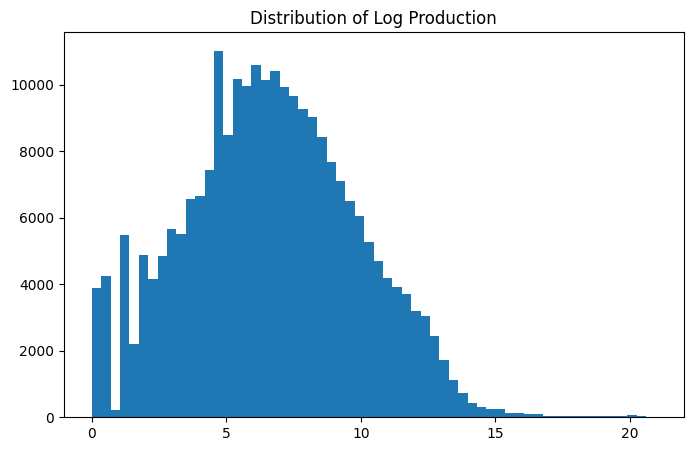

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(production["Log_Production"], bins=60)

plt.title("Distribution of Log Production")

plt.show()

In [11]:
production["Log_Area"] = np.log1p(production["Area"])

In [12]:
production = production.sort_values(
    ["State", "Crop", "Year"]
).reset_index(drop=True)

In [13]:
production["Production_Lag_1"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .shift(1)
)

In [14]:
production["Production_Lag_2"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .shift(2)
)

In [15]:
production["Production_Lag_3"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .shift(3)
)

In [16]:
production["Rolling_Mean_3"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

In [17]:
production["Rolling_Mean_5"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .transform(lambda x: x.shift(1).rolling(5).mean())
)

In [18]:
production["Rolling_STD_3"] = (
    production.groupby(["State", "Crop"])["Log_Production"]
    .transform(lambda x: x.shift(1).rolling(3).std())
)

In [19]:
production["Previous_Change"] = (
    production["Production_Lag_1"] -
    production["Production_Lag_2"]
)

In [20]:
production["Previous_Growth"] = (
    production["Previous_Change"] /
    production["Production_Lag_2"]
)

In [21]:
production["Years_From_Start"] = (
    production["Year"] -
    production["Year"].min()
)

In [22]:
production["Year_Squared"] = (
    production["Years_From_Start"] ** 2
)

In [23]:
production["Temp_Rainfall"] = (
    production["Avg_Annual_Temperature"] *
    production["Total_Annual_Rainfall"]
)

In [24]:
production["Temp_DewPoint"] = (
    production["Avg_Annual_Temperature"] *
    production["Avg_Annual_DewPoint"]
)

In [25]:
production["Rainfall_Wind"] = (
    production["Total_Annual_Rainfall"] *
    production["Avg_Annual_Wind_Speed"]
)

In [26]:
production["Area_Rainfall"] = (
    production["Log_Area"] *
    production["Total_Annual_Rainfall"]
)

In [27]:
production["Area_Temperature"] = (
    production["Log_Area"] *
    production["Avg_Annual_Temperature"]
)

In [28]:
production.isnull().sum().sort_values(ascending=False)

Rolling_Mean_5                 6057
Previous_Growth                5285
Rolling_Mean_3                 3680
Production_Lag_3               3680
Rolling_STD_3                  3680
Production_Lag_2               2471
Previous_Change                2471
Production_Lag_1               1243
State                             0
District_Name                     0
Year                              0
Season                            0
Crop                              0
Area                              0
Production                        0
Log_Production                    0
Avg_Grid_Points                   0
Avg_Annual_Surface_Pressure       0
Avg_Annual_Wind_Speed             0
Total_Annual_Rainfall             0
Avg_Annual_DewPoint               0
Avg_Annual_Temperature            0
Yield                             0
Log_Area                          0
Years_From_Start                  0
Year_Squared                      0
Temp_Rainfall                     0
Temp_DewPoint               

In [29]:
production = production.dropna().reset_index(drop=True)

In [30]:
production.shape


(233715, 31)

In [31]:
production.info()


<class 'pandas.DataFrame'>
RangeIndex: 233715 entries, 0 to 233714
Data columns (total 31 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   State                        233715 non-null  str    
 1   District_Name                233715 non-null  str    
 2   Year                         233715 non-null  int64  
 3   Season                       233715 non-null  str    
 4   Crop                         233715 non-null  str    
 5   Area                         233715 non-null  float64
 6   Production                   233715 non-null  float64
 7   Yield                        233715 non-null  float64
 8   Avg_Annual_Temperature       233715 non-null  float64
 9   Avg_Annual_DewPoint          233715 non-null  float64
 10  Total_Annual_Rainfall        233715 non-null  float64
 11  Avg_Annual_Wind_Speed        233715 non-null  float64
 12  Avg_Annual_Surface_Pressure  233715 non-null  float64
 13  Avg_Grid_P

In [32]:
production.head()


,State,District_Name,Year,Season,Crop,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points,Log_Production,Log_Area,Production_Lag_1,Production_Lag_2,Production_Lag_3,Rolling_Mean_3,Rolling_Mean_5,Rolling_STD_3,Previous_Change,Previous_Growth,Years_From_Start,Year_Squared,Temp_Rainfall,Temp_DewPoint,Rainfall_Wind,Area_Rainfall,Area_Temperature
0,Andaman And Nicobar Islands,South Andamans,2002,Whole Year,Arecanut,3105.00,5267.00,1.696296,27.209282,23.616293,60.019684,4.415234,1007.55550,10.0,8.569406,8.041091,7.642044,8.564077,7.631432,7.945851,7.999112,0.535426,-0.922032,-0.107663,5,25,1633.092508,642.582376,265.000949,482.623741,218.792313
1,Andaman And Nicobar Islands,Nicobars,2003,Whole Year,Arecanut,1261.00,1525.00,1.209358,27.149813,23.356646,65.769770,4.511707,1007.69560,10.0,7.330405,7.140453,8.569406,7.642044,8.564077,8.258509,8.192713,0.533881,0.927362,0.121350,6,36,1785.636957,634.128571,296.733932,469.625954,193.861965
2,Andaman And Nicobar Islands,South Andamans,2003,Whole Year,Arecanut,3118.00,5182.00,1.661963,27.149813,23.356646,65.769770,4.511707,1007.69560,10.0,8.553139,8.045268,7.330405,8.569406,7.642044,7.847285,7.947473,0.644495,-1.239001,-0.144584,6,36,1785.636957,634.128571,296.733932,529.135407,218.427514
3,Andaman And Nicobar Islands,Nicobars,2004,Whole Year,Arecanut,1264.70,805.85,0.637187,27.089384,23.254425,66.004180,4.381690,1007.65674,10.0,6.693138,7.143381,8.553139,7.330405,8.569406,8.150984,8.131814,0.710688,1.222734,0.166803,7,49,1788.012578,629.948049,289.209822,471.492979,193.509780
4,Andaman And Nicobar Islands,South Andamans,2004,Whole Year,Arecanut,3160.67,3975.20,1.257708,27.089384,23.254425,66.004180,4.381690,1007.65674,10.0,8.288082,8.058856,6.693138,8.553139,7.330405,7.525561,7.757627,0.945233,-1.860002,-0.217464,7,49,1788.012578,629.948049,289.209822,531.918159,218.309435


In [33]:
production.describe()


c:\Users\anurag.prajapati\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Year,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points,Log_Production,Log_Area,Production_Lag_1,Production_Lag_2,Production_Lag_3,Rolling_Mean_3,Rolling_Mean_5,Rolling_STD_3,Previous_Change,Previous_Growth,Years_From_Start,Year_Squared,Temp_Rainfall,Temp_DewPoint,Rainfall_Wind,Area_Rainfall,Area_Temperature
count,233715.000000,2.337150e+05,2.337150e+05,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,2.337150e+05,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000,233715.000000
mean,2005.810611,1.235278e+04,5.979059e+05,42.194061,24.722906,17.028006,44.790219,1.478010,963.915879,240.457570,6.766324,6.477857,6.771338,6.771910,6.768082,6.770443,6.769942,1.661166,-0.000571,inf,8.810611,101.778106,1070.561953,431.412584,58.122997,284.262924,161.032296
std,4.914401,4.934883e+04,1.733130e+07,827.235917,3.723420,3.562530,23.233793,0.598757,48.720905,134.274277,3.152973,2.767342,3.147796,3.147399,3.151969,2.705272,2.614220,1.066585,2.808002,NaN,4.914401,88.974792,485.778671,105.172401,22.905710,184.820140,74.893656
min,1997.000000,1.000000e-01,0.000000e+00,0.000000,4.529313,-1.021463,6.586140,0.298182,671.264800,1.000000,0.000000,0.095310,0.000000,0.000000,0.000000,0.006634,0.007960,0.000000,-13.981026,-1.000000e+00,0.000000,0.000000,173.754488,-5.298933,13.994842,4.565164,2.446284
25%,2002.000000,9.100000e+01,9.800000e+01,0.529101,24.962816,16.158915,31.639277,1.117055,960.100770,134.000000,4.595120,4.521789,4.605170,4.605170,4.595120,4.849781,4.914222,0.843535,-1.609438,-2.272855e-01,5.000000,25.000000,785.092665,402.606695,43.011840,158.744452,105.415494
50%,2006.000000,6.390000e+02,7.870000e+02,1.000000,25.469107,17.424799,38.721672,1.405916,976.734900,216.000000,6.669498,6.461468,6.673298,6.673298,6.672033,6.554687,6.546326,1.455372,0.000000,0.000000e+00,9.000000,81.000000,964.329197,442.903594,57.453423,252.707900,159.926130
75%,2010.000000,4.751000e+03,7.399500e+03,2.385989,26.184807,19.157621,50.070232,1.936397,989.380800,343.000000,8.909303,8.466321,8.909370,8.909370,8.909370,8.492882,8.401090,2.271314,1.606140,2.906377e-01,13.000000,169.000000,1252.439020,485.164287,72.338414,361.138327,215.541677
max,2015.000000,8.580100e+06,1.250800e+09,88000.000000,28.336908,23.765112,175.857420,4.511707,1007.695600,497.000000,20.947049,15.964956,20.947049,20.947049,20.947049,20.462553,20.056596,8.021091,13.795309,inf,18.000000,324.000000,3271.796538,662.616712,350.871177,1781.888218,398.424753


In [34]:
production.isnull().sum()

State                          0
District_Name                  0
Year                           0
Season                         0
Crop                           0
Area                           0
Production                     0
Yield                          0
Avg_Annual_Temperature         0
Avg_Annual_DewPoint            0
Total_Annual_Rainfall          0
Avg_Annual_Wind_Speed          0
Avg_Annual_Surface_Pressure    0
Avg_Grid_Points                0
Log_Production                 0
Log_Area                       0
Production_Lag_1               0
Production_Lag_2               0
Production_Lag_3               0
Rolling_Mean_3                 0
Rolling_Mean_5                 0
Rolling_STD_3                  0
Previous_Change                0
Previous_Growth                0
Years_From_Start               0
Year_Squared                   0
Temp_Rainfall                  0
Temp_DewPoint                  0
Rainfall_Wind                  0
Area_Rainfall                  0
Area_Tempe

In [38]:
production.isnull().sum().sort_values(ascending=False)

State                          0
District_Name                  0
Year                           0
Season                         0
Crop                           0
Area                           0
Production                     0
Avg_Annual_Temperature         0
Avg_Annual_DewPoint            0
Total_Annual_Rainfall          0
Avg_Annual_Wind_Speed          0
Avg_Annual_Surface_Pressure    0
Avg_Grid_Points                0
Log_Production                 0
Log_Area                       0
Production_Lag_1               0
Production_Lag_2               0
Production_Lag_3               0
Rolling_Mean_3                 0
Rolling_Mean_5                 0
Rolling_STD_3                  0
Previous_Change                0
Previous_Growth                0
Years_From_Start               0
Year_Squared                   0
Temp_Rainfall                  0
Temp_DewPoint                  0
Rainfall_Wind                  0
Area_Rainfall                  0
Area_Temperature               0
dtype: int

In [39]:
production = production.dropna().reset_index(drop=True)

In [40]:
production.isnull().sum()

State                          0
District_Name                  0
Year                           0
Season                         0
Crop                           0
Area                           0
Production                     0
Avg_Annual_Temperature         0
Avg_Annual_DewPoint            0
Total_Annual_Rainfall          0
Avg_Annual_Wind_Speed          0
Avg_Annual_Surface_Pressure    0
Avg_Grid_Points                0
Log_Production                 0
Log_Area                       0
Production_Lag_1               0
Production_Lag_2               0
Production_Lag_3               0
Rolling_Mean_3                 0
Rolling_Mean_5                 0
Rolling_STD_3                  0
Previous_Change                0
Previous_Growth                0
Years_From_Start               0
Year_Squared                   0
Temp_Rainfall                  0
Temp_DewPoint                  0
Rainfall_Wind                  0
Area_Rainfall                  0
Area_Temperature               0
dtype: int

In [41]:
production.columns

Index(['State', 'District_Name', 'Year', 'Season', 'Crop', 'Area',
       'Production', 'Avg_Annual_Temperature', 'Avg_Annual_DewPoint',
       'Total_Annual_Rainfall', 'Avg_Annual_Wind_Speed',
       'Avg_Annual_Surface_Pressure', 'Avg_Grid_Points', 'Log_Production',
       'Log_Area', 'Production_Lag_1', 'Production_Lag_2', 'Production_Lag_3',
       'Rolling_Mean_3', 'Rolling_Mean_5', 'Rolling_STD_3', 'Previous_Change',
       'Previous_Growth', 'Years_From_Start', 'Year_Squared', 'Temp_Rainfall',
       'Temp_DewPoint', 'Rainfall_Wind', 'Area_Rainfall', 'Area_Temperature'],
      dtype='str')

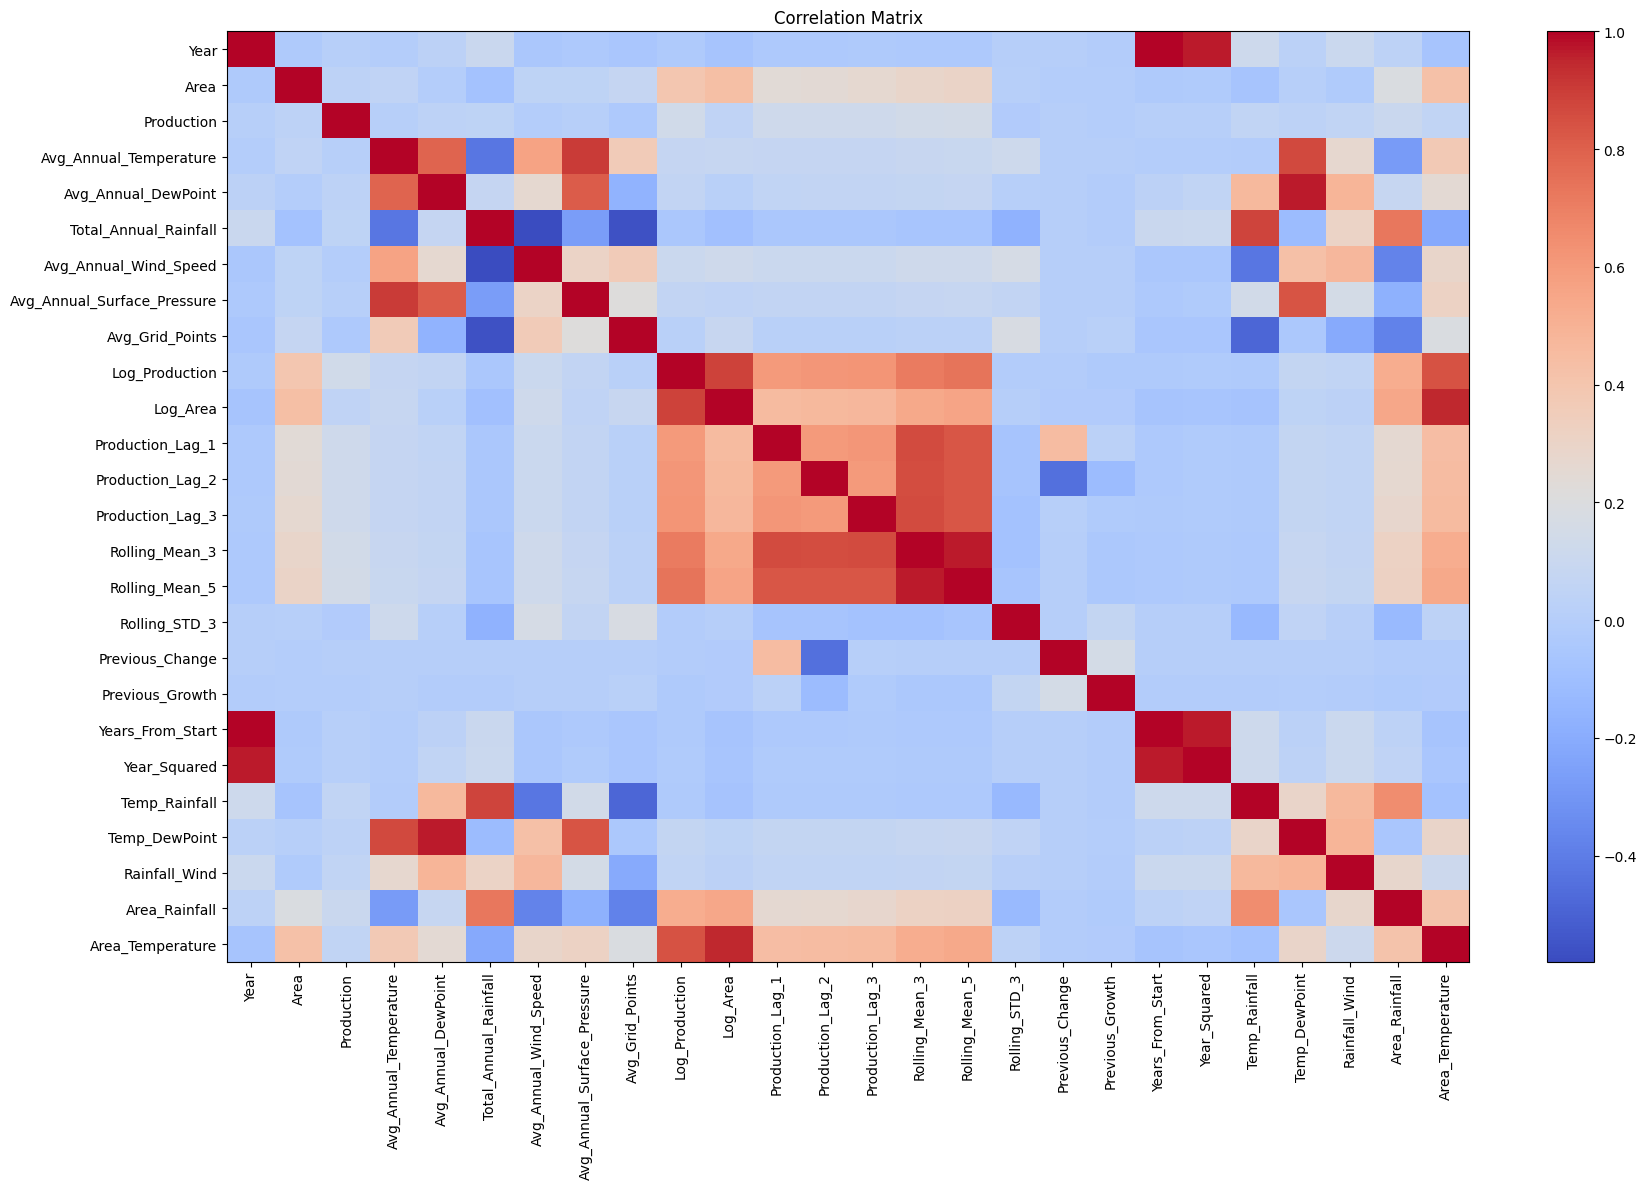

In [42]:
import matplotlib.pyplot as plt

numeric = production.select_dtypes(include=np.number)

corr = numeric.corr()

plt.figure(figsize=(18, 12))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

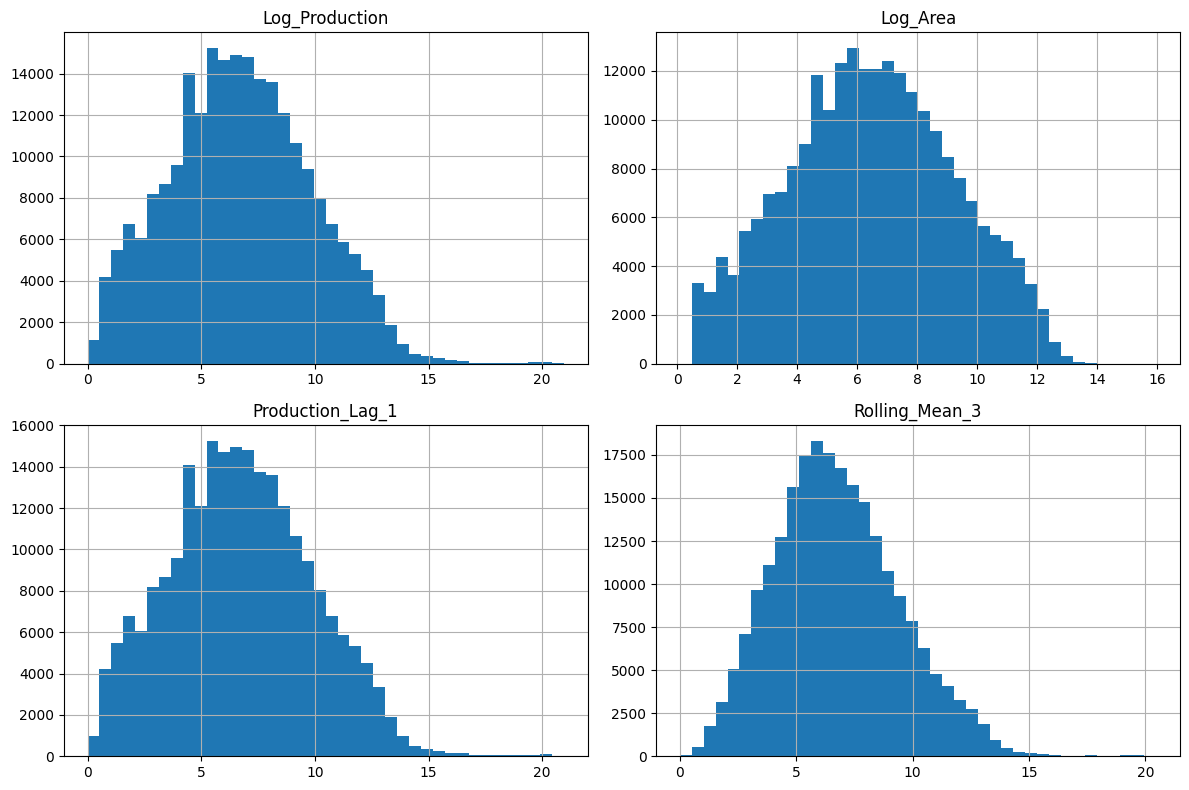

In [43]:
production[
    [
        "Log_Production",
        "Log_Area",
        "Production_Lag_1",
        "Rolling_Mean_3",
    ]
].hist(figsize=(12, 8), bins=40)

plt.tight_layout()
plt.show()

In [36]:
production = production.drop(columns=["Yield"])

production.to_csv(
    "../datasets/processed/production_features.csv",
    index=False
)